# 03 – Robustheit, Seed-Reproduzierbarkeit und Attractor-Kandidaten

Dieses Notebook prüft die Rohlabels gegen reproduzierbare 1-nm-Jitter und
kombiniert die Seminarheuristiken. Jitter-Labels werden nie durch den
Persistenzfilter "robuster" gemacht. Kandidaten sind heuristische Hinweise und
keine formalen Attraktorbeweise.

In [1]:
import sys
from pathlib import Path
from zlib import crc32

PROJECT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.contact_graphs import contact_graph, pair_table
from src.macrostates import macrostate_from_graph
from src.pipeline import GRAPH_TYPES, load_team1_data
from src.plots import save_fig, setup_style
from src.robustness import jitter_positions
from src.sequences import attractor_candidate

setup_style()
OUT = PROJECT / 'data' / 'processed'
TEAM1_DATA = PROJECT.parent / 'team1_forces' / 'data' / 'processed'
BOX = 20e-6
SIGMA_NM = 1.0
STATE_ORDER = [
    'monomer_gas', 'dimer_dominated', 'trimer_like', 'tetra_like',
    'loose_four_cluster', 'large_cluster', 'mixed_transition',
]
pd.set_option('display.max_columns', 40)

positions, parameters = load_team1_data(TEAM1_DATA, box=BOX)
sequences = pd.read_csv(OUT / 'macrostate_sequences.csv')
metrics = pd.read_csv(OUT / 'sequence_metrics.csv')
dwell = pd.read_csv(OUT / 'dwell_times.csv')

## Jitter-Robustheit der Rohlabels

Der Seed wird ohne Pythons randomisiertes `hash()` aus Run-ID, Zeit und
Graphdefinition abgeleitet (CRC32). Für jeden Frame wird dieselbe Paartabelle
für alle drei Graphen verwendet. Negative Oberflächenabstände bleiben als
Überlappungsdiagnosen sichtbar.

In [2]:
def stable_jitter_seed(run_id, time, graph_type):
    text = f'team2-jitter|{run_id}|{time!r}|{graph_type}'
    return crc32(text.encode('utf-8')) & 0xffffffff

robustness_rows = []
for run_id, run_positions in positions.groupby('run_id', sort=True):
    run_sequences = sequences[sequences.run_id == run_id].sort_values('time')
    first = run_positions.iloc[0]
    expected = run_sequences[run_sequences.graph_type == 'meso'].macrostate_raw.tolist()
    for frame_index, (time, frame) in enumerate(run_positions.groupby('time', sort=True)):
        frame = frame.sort_values('particle_id')
        ids = frame.particle_id.tolist()
        xyz = frame[['x', 'y']].to_numpy()
        pairs = pair_table(xyz, ids, R=first.R_nm * 1e-9, box=BOX)
        perturbed_xyz = jitter_positions(
            xyz, sigma_nm=SIGMA_NM, seed=stable_jitter_seed(run_id, time, 'base'),
            box=BOX,
        )
        perturbed_pairs = pair_table(
            perturbed_xyz, ids, R=first.R_nm * 1e-9, box=BOX,
        )
        for graph_type in GRAPH_TYPES:
            raw_label = macrostate_from_graph(contact_graph(pairs, ids, graph_type=graph_type))
            jitter_label = macrostate_from_graph(
                contact_graph(perturbed_pairs, ids, graph_type=graph_type)
            )
            if graph_type == 'meso':
                assert raw_label == expected[frame_index]
            robustness_rows.append({
                'run_id': run_id, 'seed': first.seed, 'time': time,
                'model_type': first.model_type,
                'material_type': first.material_type,
                'n_particles': int(run_sequences.n_particles.iloc[0]),
                'graph_type': graph_type, 'sigma_nm': SIGMA_NM,
                'raw_macrostate': raw_label, 'jitter_macrostate': jitter_label,
                'label_agreement': float(raw_label == jitter_label),
            })

robustness = pd.DataFrame(robustness_rows)
robustness.to_csv(OUT / 'label_robustness.csv', index=False)
print(f'Jitter-Zeilen: {len(robustness)}')
display(robustness.groupby('graph_type').label_agreement.agg(['mean', 'min']).rename(columns={
    'mean': 'mittlere Label-Übereinstimmung', 'min': 'Minimum'
}))

Jitter-Zeilen: 57000


,mittlere Label-Übereinstimmung,Minimum
graph_type,,
hard,0.891737,0.0
meso,0.999263,0.0
near,0.984474,0.0


## Kriterien pro Lauf und Gruppe

Der seed_count eines Zustands zählt, in wie vielen Läufen eines
Modell/Material/Graph-Blocks er in der gefilterten Sequenz vorkommt.
`total_seeds` zählt sämtliche Läufe desselben Blocks. Mit einem Seed bleibt
Seed-Reproduzierbarkeit dadurch ausdrücklich nicht bestimmbar.

In [3]:
run_agreement = robustness.groupby(
    ['run_id', 'seed', 'model_type', 'material_type', 'n_particles', 'graph_type'],
    sort=True,
).label_agreement.mean().rename('label_agreement').reset_index()
agreement_lookup = run_agreement.set_index(['run_id', 'graph_type']).label_agreement

state_seed_counts = pd.concat([
    sequences.assign(state=sequences.macrostate_raw, sequence_type='raw'),
    sequences.assign(state=sequences.macrostate_filtered, sequence_type='filtered'),
]).groupby(
    ['n_particles', 'model_type', 'material_type', 'graph_type', 'sequence_type', 'state'],
).seed.nunique()
group_seeds = (
    sequences
    .groupby(['n_particles', 'model_type', 'material_type', 'graph_type'])
    .seed.nunique()
)

def seed_counts(row):
    key = (int(row.n_particles), row.model_type, row.material_type,
           row.graph_type, row.sequence_type, row.state)
    if key in state_seed_counts:
        return int(state_seed_counts.loc[key])
    return 0

metrics = metrics.copy()
metrics['label_agreement'] = [
    agreement_lookup.loc[(row.run_id, row.graph_type)] for row in metrics.itertuples()
]
metrics['seed_count_in_state'] = [seed_counts(row) for row in metrics.itertuples()]
metrics['total_seeds'] = [
    int(group_seeds.loc[(int(row.n_particles), row.model_type,
                         row.material_type, row.graph_type)])
    for row in metrics.itertuples()
]
metrics.to_csv(OUT / 'sequence_metrics.csv', index=False)
display(run_agreement)

,run_id,seed,model_type,material_type,n_particles,graph_type,label_agreement
0,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,hard,0.999
1,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,meso,0.997
2,cl_retarded_A5.0e-21_I100_N20_s0,0,cl_retarded,PMBC,20,near,0.993
3,cl_retarded_A5.0e-21_I100_N20_s1,1,cl_retarded,PMBC,20,hard,1.000
4,cl_retarded_A5.0e-21_I100_N20_s1,1,cl_retarded,PMBC,20,meso,1.000
5,cl_retarded_A5.0e-21_I100_N20_s1,1,cl_retarded,PMBC,20,near,0.996
6,cl_retarded_A5.0e-21_I100_N20_s42,42,cl_retarded,PMBC,20,hard,0.999
7,cl_retarded_A5.0e-21_I100_N20_s42,42,cl_retarded,PMBC,20,meso,0.999
8,cl_retarded_A5.0e-21_I100_N20_s42,42,cl_retarded,PMBC,20,near,0.997
9,cl_retarded_A5.0e-21_I100_N50_s42,42,cl_retarded,PMBC,50,hard,1.000


## Attractor-Kandidaten nach Seminarheuristik

Aggregate werden aus den gefilterten N=20-Sequenzen gebildet. Frequenz ist über
Frames gewichtet; return probability wird aus gepoolten Abgängen und Rückkehren
berechnet. Ein unvollständiger Kriteriumswert kann niemals als „erfüllt“ gelten.
Alle sechs N=20-Modell/Material-Blätter erfüllen die Drei-Seed-Schwelle; der
getrennte N=50-Lauf bleibt außerhalb dieses Kandidatenvergleichs.


In [4]:
candidate_rows = []
groups = metrics[
    (metrics.n_particles == 20) & (metrics.sequence_type == 'filtered')
].groupby(['n_particles', 'model_type', 'material_type', 'graph_type'], sort=True)
for (n_particles, model, material, graph_type), group in groups:
    group_runs = group.run_id.nunique()
    dwell_group = dwell[
        (dwell.n_particles == 20) & (dwell.graph_type == graph_type)
        & (dwell.sequence_type == 'filtered')
        & (dwell.model_type == model) & (dwell.material_type == material)
    ]
    label_agreement = run_agreement[
        (run_agreement.n_particles == 20)
        & (run_agreement.model_type == model)
        & (run_agreement.material_type == material)
        & (run_agreement.graph_type == graph_type)
    ].label_agreement.mean()
    for state in [s for s in STATE_ORDER if s in set(group.state)]:
        state_metrics = group[group.state == state]
        frequency = np.average(
            state_metrics.frequency, weights=state_metrics.n_frames
        )
        state_dwell = dwell_group[dwell_group.state == state].dwell_steps
        eligible = int(state_metrics.return_eligible_T50.sum())
        returns = int(state_metrics.returns_T50.sum())
        return_probability = returns / eligible if eligible else np.nan
        return_times = state_metrics.dropna(subset=['mean_return_steps_T200'])
        returns_T200 = int(state_metrics.returns_T200.sum())
        if returns_T200:
            mean_return_T200 = np.average(
                return_times.mean_return_steps_T200,
                weights=return_times.returns_T200,
            )
        else:
            mean_return_T200 = np.nan
        flags = attractor_candidate(
            frequency=frequency,
            mean_dwell_steps=state_dwell.mean() if len(state_dwell) else np.nan,
            return_probability=return_probability,
            seed_count=state_metrics.seed_count_in_state.iloc[0],
            label_agreement=label_agreement,
            total_seeds=group_runs,
        )
        candidate_rows.append({
            'n_particles': n_particles, 'model_type': model,
            'material_type': material, 'graph_type': graph_type, 'state': state,
            'frequency': frequency, 'mean_dwell_steps': float(state_dwell.mean()) if len(state_dwell) else np.nan,
            'return_probability_T50': return_probability,
            'mean_return_steps_T200': mean_return_T200,
            'seed_count': int(state_metrics.seed_count_in_state.iloc[0]),
            'total_seeds': group_runs, 'label_agreement': label_agreement,
            **flags,
        })

candidates = pd.DataFrame(candidate_rows)
candidates.to_csv(OUT / 'attractor_candidates.csv', index=False)
display(candidates)
print('Gesamtanzahl Kandidaten:', int(candidates.candidate.sum()))

,n_particles,model_type,material_type,graph_type,state,frequency,mean_dwell_steps,return_probability_T50,mean_return_steps_T200,seed_count,total_seeds,label_agreement,frequency_ok,mean_dwell_ok,return_probability_ok,seed_reproducibility,label_agreement_ok,candidate
0,20,cl_retarded,PMBC,hard,monomer_gas,0.023000,23.000000,0.0,NaN,3,3,0.999333,False,True,False,True,True,False
1,20,cl_retarded,PMBC,hard,dimer_dominated,0.017000,17.000000,0.0,NaN,2,3,0.999333,False,True,False,False,True,False
2,20,cl_retarded,PMBC,hard,trimer_like,0.014000,14.000000,0.0,NaN,2,3,0.999333,False,True,False,False,True,False
3,20,cl_retarded,PMBC,hard,tetra_like,0.953000,953.000000,NaN,NaN,3,3,0.999333,True,True,None,True,True,False
4,20,cl_retarded,PMBC,hard,loose_four_cluster,0.010000,10.000000,0.0,NaN,1,3,0.999333,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62,20,vdw_only,fatty_acid,near,monomer_gas,0.070333,70.333333,0.0,NaN,3,3,0.978000,True,True,False,True,True,False
63,20,vdw_only,fatty_acid,near,dimer_dominated,0.098333,49.166667,0.5,18.0,3,3,0.978000,True,True,True,True,True,True
64,20,vdw_only,fatty_acid,near,trimer_like,0.025500,17.000000,0.0,56.0,2,3,0.978000,False,True,False,False,True,False
65,20,vdw_only,fatty_acid,near,tetra_like,0.808000,808.000000,NaN,NaN,3,3,0.978000,True,True,None,True,True,False


Gesamtanzahl Kandidaten: 4


## Abbildung 6 – Label Agreement nach Jitter

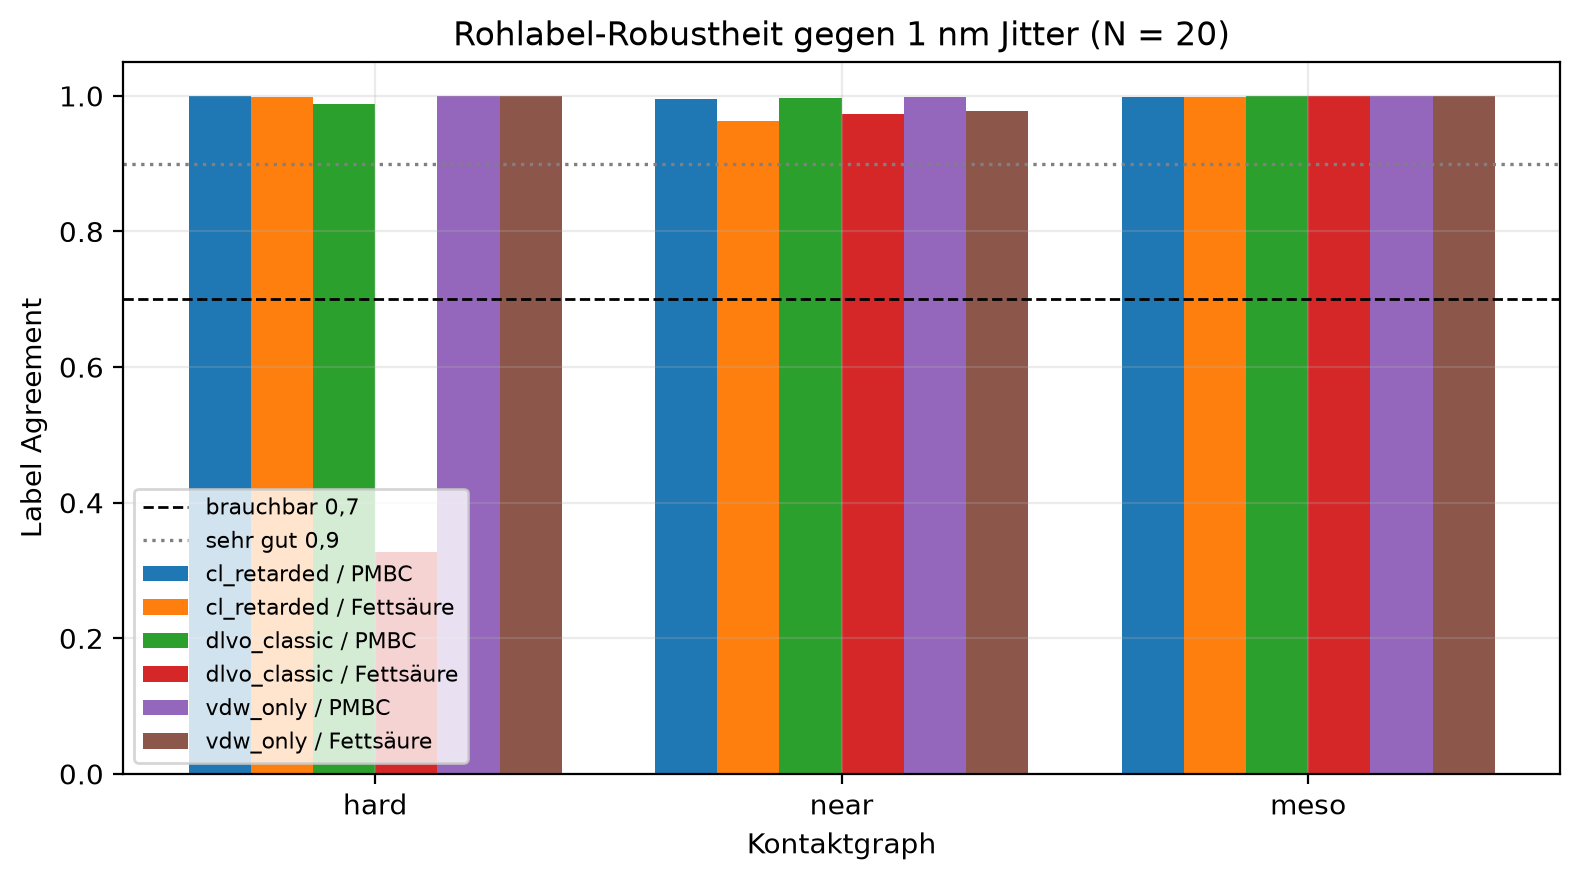

In [5]:
plot_robustness = robustness[robustness.n_particles == 20]
groups = sorted(plot_robustness.groupby(['model_type', 'material_type']).groups)
graph_types = list(GRAPH_TYPES)
x = np.arange(len(graph_types))
width = 0.8 / max(len(groups), 1)
material_german = {'fatty_acid': 'Fettsäure', 'PMBC': 'PMBC', 'unknown': 'unbestimmt'}
fig, ax = plt.subplots(figsize=(8, 4.5))
for index, (model, material) in enumerate(groups):
    values = plot_robustness[
        (plot_robustness.model_type == model) & (plot_robustness.material_type == material)
    ].groupby('graph_type').label_agreement.mean()
    heights = [values.get(graph_type, np.nan) for graph_type in graph_types]
    ax.bar(x + index * width, heights, width, label=f'{model} / {material_german[material]}')
ax.axhline(0.7, color='black', linestyle='--', linewidth=1, label='brauchbar 0,7')
ax.axhline(0.9, color='grey', linestyle=':', linewidth=1.2, label='sehr gut 0,9')
ax.set_xticks(x + 0.4 - width / 2, graph_types)
ax.set_ylim(0, 1.05)
ax.set_xlabel('Kontaktgraph')
ax.set_ylabel('Label Agreement')
ax.set_title('Rohlabel-Robustheit gegen 1 nm Jitter (N = 20)')
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, '06_label_agreement_jitter')
plt.show()

## Abbildung 7 – Fettsäurevesikel vs. PMBC

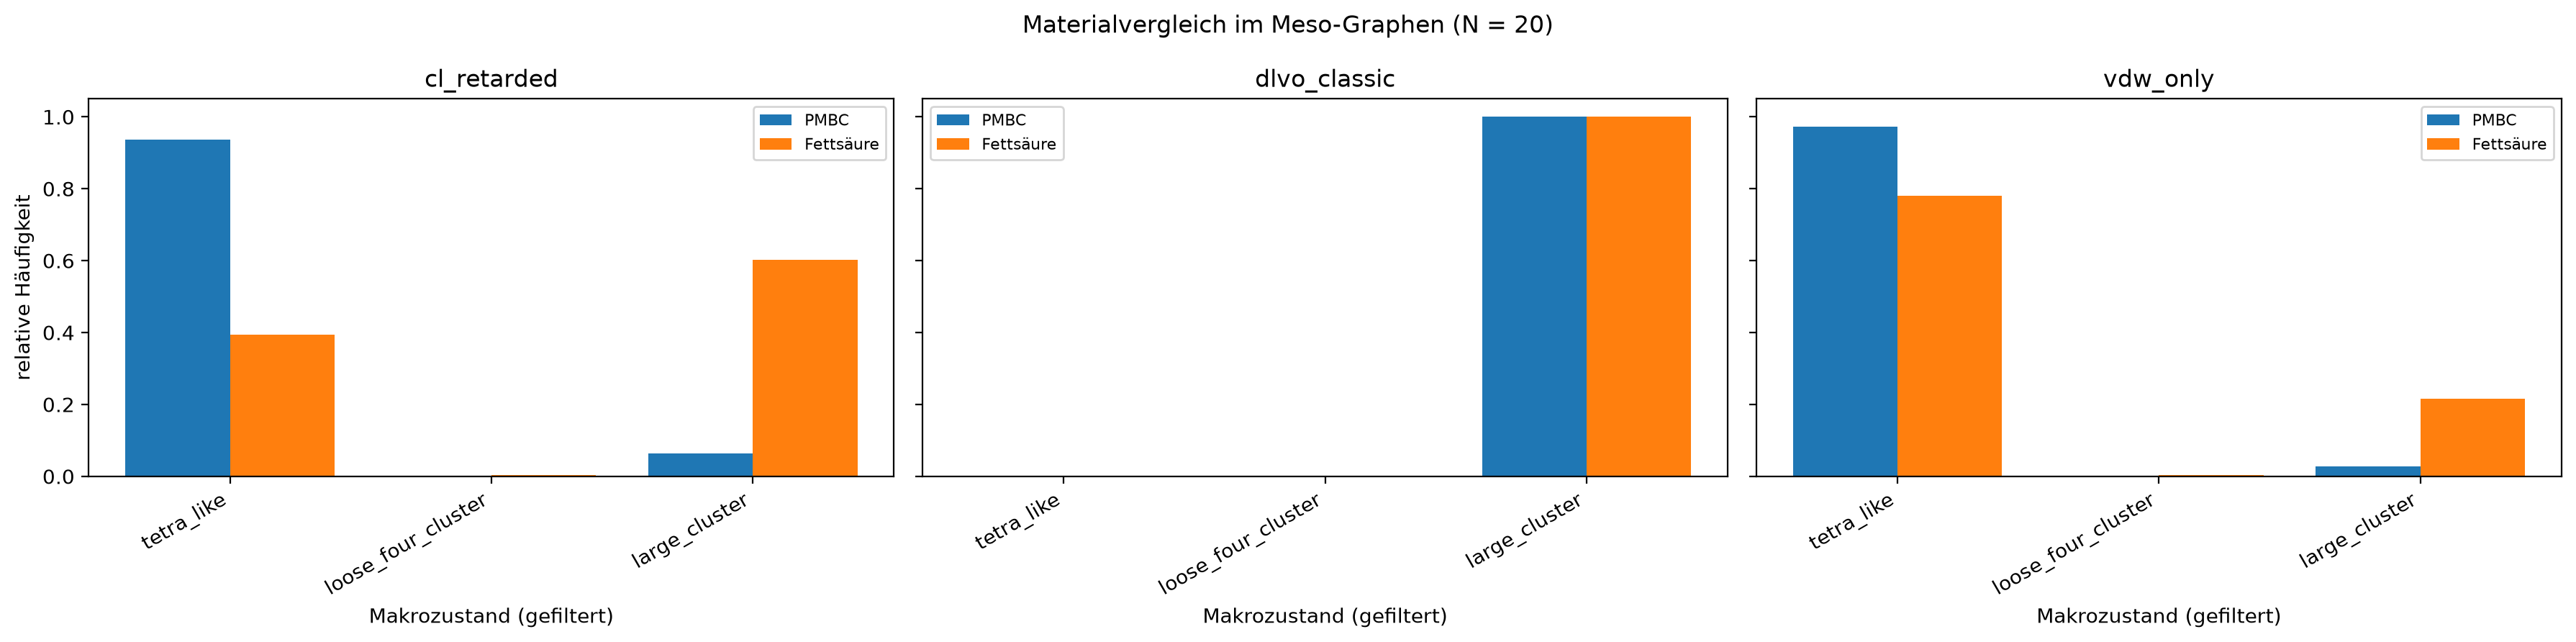

Hinweis: jeder N=20-Modell/Material-Block hat drei Seeds; der N=50-Lauf ist getrennt.
Kandidaten sind heuristische Hinweise und keine formalen Attraktorbeweise.


In [6]:
comparison = sequences[
    (sequences.n_particles == 20) & (sequences.graph_type == 'meso')
    & (sequences.macrostate_filtered.notna())
]
states = [s for s in STATE_ORDER if s in set(comparison.macrostate_filtered)]
models = sorted(comparison.model_type.unique())
materials = sorted(comparison.material_type.unique())
colors = {'fatty_acid': 'tab:orange', 'PMBC': 'tab:blue', 'unknown': 'tab:grey'}
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 4.5), sharey=True, squeeze=False)
for ax, model in zip(axes[0], models):
    model_data = comparison[comparison.model_type == model]
    x = np.arange(len(states))
    width = 0.8 / max(len(materials), 1)
    for index, material in enumerate(materials):
        material_data = model_data[model_data.material_type == material]
        frequencies = material_data.macrostate_filtered.value_counts(normalize=True)
        values = [frequencies.get(state, 0.0) for state in states]
        ax.bar(
            x + index * width, values, width,
            label=material_german.get(material, material),
            color=colors.get(material),
        )
    ax.set_xticks(x + 0.4 - width / 2, states, rotation=30, ha='right')
    ax.set_title(model)
    ax.set_xlabel('Makrozustand (gefiltert)')
    ax.legend(fontsize=8)
    ax.grid(False)
axes[0][0].set_ylabel('relative Häufigkeit')
fig.suptitle('Materialvergleich im Meso-Graphen (N = 20)')
fig.tight_layout()
save_fig(fig, '07_materialvergleich')
plt.show()

print('Hinweis: jeder N=20-Modell/Material-Block hat drei Seeds; der N=50-Lauf ist getrennt.')
print('Kandidaten sind heuristische Hinweise und keine formalen Attraktorbeweise.')
